# Price Prediction

In [1]:
%pip install -q catboost

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split, ParameterSampler, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, PolynomialFeatures, TargetEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Load Data

<div dir="rtl">

متن آگهی‌ها (`title` و `description`) لازم نیست، چون ستون‌های `mentions_X` از قبل از متن ساخته شده‌اند.

</div>

In [3]:
df = pd.read_parquet('divar_clean.parquet')
df = df.drop(columns=['title', 'description'])
df.shape

(997409, 86)

## Data Selection

<div dir="rtl">

- فقط آگهی‌های فروش و اجاره. متغیر هدف `unified_price` است.
- آگهی‌های `is_wanted_ad` و `is_partial_offer` حذف می‌شوند، چون قیمتشان قیمت کل ملک نیست.
- آگهی‌های بدون متراژ حذف می‌شوند، چون بعداً قیمت هر متر لازم داریم.
- فقط بازه‌ی اصلی (`in_main_window`) می‌ماند، چون ماه آگهی یکی از featureهاست و ماه‌های بیرون از این بازه خیلی کم‌اند.

</div>

In [4]:
keep = (df['deal_type'].isin(['sale', 'rent'])
        & df['unified_price'].notna()
        & df['building_size'].notna()
        & ~df['is_wanted_ad']
        & ~df['is_partial_offer']
        & df['in_main_window'])
df = df[keep].copy()
df.shape

(857009, 86)

In [5]:
df['deal_type'].value_counts()

,count
deal_type,
sale,527284
rent,329725


## Features

<div dir="rtl">

- ستون‌های قیمت و هر چیزی که از قیمت ساخته شده وارد X نمی‌شوند.
- ستون‌های boolean به ۰ و ۱ تبدیل می‌شوند و missing همان missing می‌ماند.
- ماه آگهی به عدد تبدیل می‌شود تا اثر تورم را بگیرد.
- ستون‌های متنی فرم (نوع سند، نوع اجاره، گرمایش، سرمایش و ...) فقط در مدل‌های درختی استفاده می‌شوند، چون این مدل‌ها ستون categorical را مستقیم می‌پذیرند.

</div>

In [6]:
numeric_cols = ['building_size', 'land_size', 'rooms_count', 'construction_year', 'floor',
                'total_floors_count', 'unit_per_floor', 'location_latitude', 'location_longitude']
bool_cols = ['has_elevator', 'has_parking', 'has_warehouse', 'is_rebuilt', 'is_metro',
             'has_balcony_combined', 'has_security_guard_combined', 'has_pool_combined',
             'has_sauna_combined', 'has_jacuzzi_combined', 'has_barbecue_combined',
             'has_business_deed', 'rent_credit_transform', 'transformable_price']
keyword_cols = [c for c in df.columns if c.startswith('mentions_')]
cat_cols = ['cat3_slug', 'city_slug', 'neighborhood_slug']
form_cols = ['deed_type', 'rent_type', 'floor_material', 'has_heating_system', 'has_cooling_system',
             'has_warm_water_provider', 'building_direction', 'user_type']

In [7]:
X = df[numeric_cols + bool_cols + keyword_cols + cat_cols + form_cols + ['deal_type']].copy()
X[bool_cols + keyword_cols] = X[bool_cols + keyword_cols].astype(float)
X['month'] = df['created_at_month'].dt.month - 4  # 1 = May 2024
y = df['unified_price']
X.shape

(857009, 48)

In [8]:
X.isna().mean().sort_values(ascending=False).head(10).round(3)

,0
has_business_deed,0.971
has_barbecue_combined,0.967
has_sauna_combined,0.964
has_jacuzzi_combined,0.961
has_pool_combined,0.950
has_security_guard_combined,0.909
rent_type,0.884
land_size,0.806
deed_type,0.724
user_type,0.698


## Train / Validation / Test Split

<div dir="rtl">

داده به نسبت ۸۰، ۱۰ و ۱۰ درصد تقسیم می‌شود و نسبت فروش و اجاره در هر سه بخش یکسان می‌ماند. حدهای outlier، hyperparameterها و انتخاب مدل فقط با train و validation تعیین می‌شوند و test فقط یک بار در آخر استفاده می‌شود.

</div>

In [9]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, stratify=X['deal_type'], random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=X_temp['deal_type'], random_state=42)
len(X_train), len(X_val), len(X_test)

(685607, 85701, 85701)

In [10]:
pd.DataFrame({'train': X_train['deal_type'].value_counts(),
              'val': X_val['deal_type'].value_counts(),
              'test': X_test['deal_type'].value_counts()})

,train,val,test
deal_type,,,
sale,421827,52729,52728
rent,263780,32972,32973


## Data Overview

<div dir="rtl">

جدول‌ها و نمودارهای این بخش فقط از train ساخته شده‌اند.

</div>

In [11]:
price_per_m2 = y_train / X_train['building_size']
by_category = X_train.groupby('cat3_slug')
overview = pd.DataFrame({
    'ads': by_category.size(),
    'share of ads (%)': by_category.size() / len(X_train) * 100,
    'median price (M toman)': (y_train / 1e6).groupby(X_train['cat3_slug']).median(),
    'median size (m²)': by_category['building_size'].median(),
    'median price per m² (M toman)': (price_per_m2 / 1e6).groupby(X_train['cat3_slug']).median()})
overview.round(1)

,ads,share of ads (%),median price (M toman),median size (m²),median price per m² (M toman)
cat3_slug,,,,,
apartment-rent,161811,23.6,550.0,95.0,6.0
apartment-sell,230174,33.6,3400.0,90.0,36.7
house-villa-rent,47772,7.0,316.7,100.0,3.2
house-villa-sell,85848,12.5,2900.0,130.0,23.1
industry-agriculture-business-rent,5990,0.9,800.0,400.0,2.3
industry-agriculture-business-sell,6207,0.9,3132.0,1250.0,2.2
office-rent,14475,2.1,933.3,90.0,11.0
office-sell,3293,0.5,7500.0,85.0,90.0
plot-old,82929,12.1,1400.0,250.0,4.7


<div dir="rtl">

- آپارتمان (فروش و اجاره) ۵۷ درصد آگهی‌هاست؛ دفتر، مغازه و ملک صنعتی و کشاورزی هر کدام کمتر از ۵ درصدند.
- median قیمت هر متر بین دسته‌ها حدود ۵۰ برابر فرق دارد (از ۲.۲ تا ۱۰۸ میلیون تومان)، پس `cat3_slug` باید در همه‌ی مدل‌ها باشد.

</div>

### Price and Size

<div dir="rtl">

رابطه‌ی قیمت و متراژ در مقیاس log-log، و شیب خط برازش‌شده برای هر دسته:

</div>

In [12]:
slopes = {}
for cat, rows in X_train.groupby('cat3_slug'):
    slopes[cat] = np.polyfit(np.log(rows['building_size']), np.log(y_train[rows.index]), 1)[0]
pd.Series(slopes).sort_values().round(2)

industry-agriculture-business-rent    0.18
industry-agriculture-business-sell    0.31
plot-old                              0.37
shop-rent                             0.66
shop-sell                             0.69
house-villa-sell                      0.81
office-rent                           1.01
house-villa-rent                      1.04
office-sell                           1.17
apartment-rent                        1.33
apartment-sell                        1.38
dtype: float64

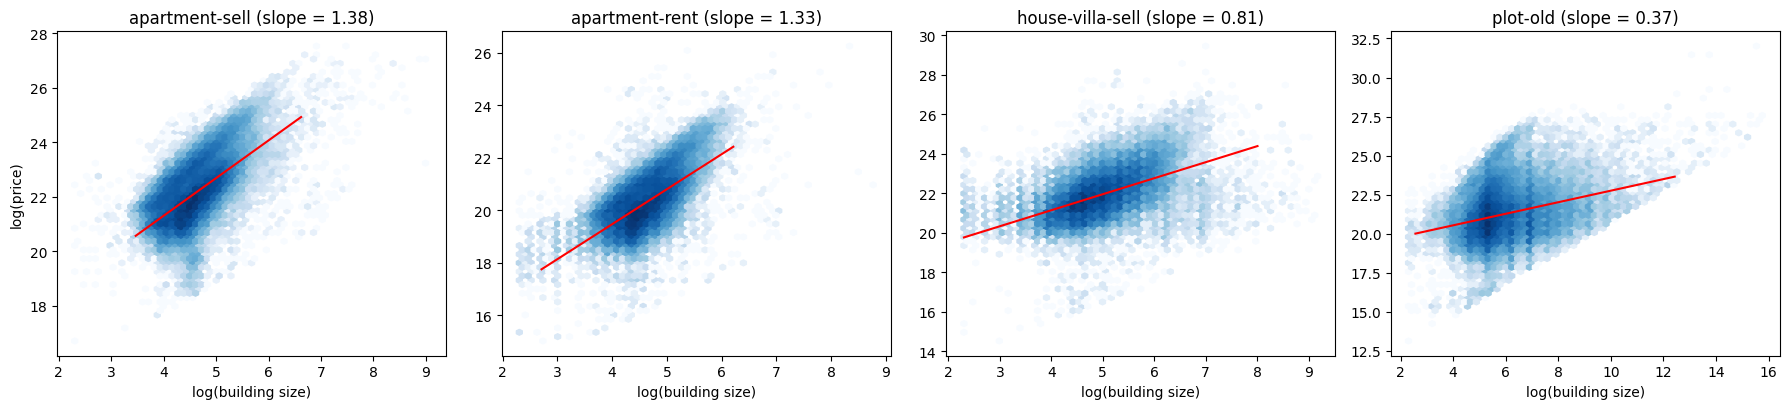

In [13]:
panels = ['apartment-sell', 'apartment-rent', 'house-villa-sell', 'plot-old']
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, cat in zip(axes, panels):
    rows = X_train['cat3_slug'] == cat
    log_size = np.log(X_train.loc[rows, 'building_size'])
    log_price = np.log(y_train[rows])
    slope, intercept = np.polyfit(log_size, log_price, 1)
    ax.hexbin(log_size, log_price, gridsize=60, bins='log', cmap='Blues')
    x = log_size.quantile([0.001, 0.999]).values
    ax.plot(x, slope * x + intercept, color='red')
    ax.set_title(f'{cat} (slope = {slope:.2f})')
    ax.set_xlabel('log(building size)')
axes[0].set_ylabel('log(price)')
plt.tight_layout()
plt.show()

<div dir="rtl">

- رابطه در مقیاس log-log تقریباً خطی است، پس متراژ هم مثل قیمت با log وارد مدل‌های خطی می‌شود. در زمین پراکندگی دور خط خیلی بیشتر از آپارتمان است.
- شیب از ۰.۱۸ تا ۱.۳۸ تغییر می‌کند. یک ضریب مشترک برای متراژ کافی نیست و ضرب متراژ در `cat3_slug` لازم است.
- شیب آپارتمان از ۱ بیشتر است، یعنی آپارتمان‌های بزرگ‌تر قیمت هر متر بالاتری دارند. در زمین و ملک صنعتی و کشاورزی برعکس است.

</div>

### Location

<div dir="rtl">

قیمت هر متر آپارتمان فروشی در ۱۵ شهر بزرگ، و روی نقشه‌ی تهران:

</div>

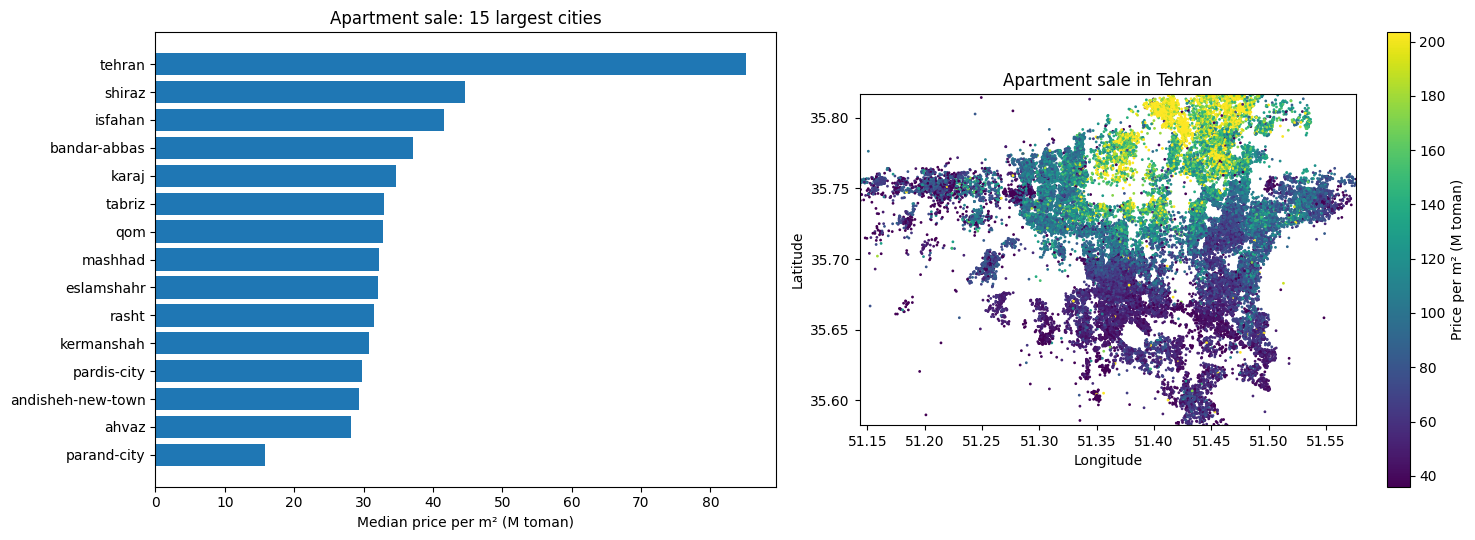

In [14]:
apartments = X_train['cat3_slug'] == 'apartment-sell'
ppm2 = price_per_m2[apartments] / 1e6
city = X_train.loc[apartments, 'city_slug']
city_median = ppm2.groupby(city).median()[city.value_counts().head(15).index].sort_values()

tehran = X_train[apartments & (X_train['city_slug'] == 'tehran') & X_train['location_latitude'].notna()]
tehran_ppm2 = ppm2[tehran.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh(city_median.index, city_median.values)
axes[0].set_xlabel('Median price per m² (M toman)')
axes[0].set_title('Apartment sale: 15 largest cities')
# colours are clipped at the 5th and 95th percentiles
points = axes[1].scatter(tehran['location_longitude'], tehran['location_latitude'], c=tehran_ppm2, s=1,
                         cmap='viridis', vmin=tehran_ppm2.quantile(0.05), vmax=tehran_ppm2.quantile(0.95))
axes[1].set_xlim(tehran['location_longitude'].quantile([0.005, 0.995]))
axes[1].set_ylim(tehran['location_latitude'].quantile([0.005, 0.995]))
axes[1].set_aspect(1 / np.cos(np.radians(35.7)))
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].set_title('Apartment sale in Tehran')
fig.colorbar(points, ax=axes[1], label='Price per m² (M toman)')
plt.tight_layout()
plt.show()

In [15]:
log_ppm2 = np.log(ppm2)
neighborhood = X_train.loc[apartments, 'neighborhood_slug'].fillna('none')

# share of the variance of log(price per m²) explained by the group means
def variance_explained(keys):
    group_mean = log_ppm2.groupby(keys).transform('mean')
    return 1 - ((log_ppm2 - group_mean) ** 2).sum() / ((log_ppm2 - log_ppm2.mean()) ** 2).sum()

pd.Series({'city': variance_explained(city),
           'city + neighborhood': variance_explained([city, neighborhood])}).round(2)

city                   0.55
city + neighborhood    0.75
dtype: float64

<div dir="rtl">

- شهر به‌تنهایی ۵۵ درصد واریانس log قیمت هر متر آپارتمان فروشی را توضیح می‌دهد و همراه با محله ۷۵ درصد. موقعیت مهم‌ترین گروه featureهاست.
- قیمت هر متر در تهران حدود دو برابر شهرهای بعدی است.
- داخل تهران قیمت از جنوب به شمال پیوسته بالا می‌رود و به مرز محله‌ها محدود نیست. برای همین قیمت آگهی‌های نزدیک (`neighbor_price`) هم به‌عنوان feature ساخته می‌شود.

</div>

### Property Features

<div dir="rtl">

نسبت median قیمت هر متر آپارتمان‌های فروشی با و بدون هر ویژگی، و اثر سال ساخت:

</div>

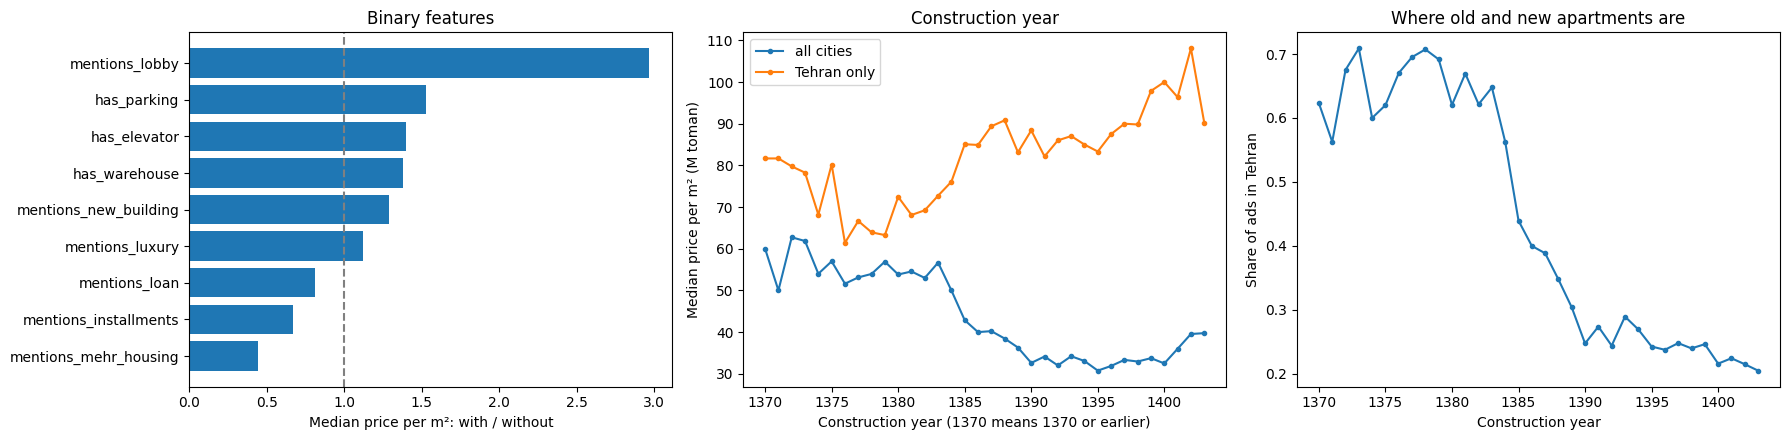

In [16]:
flags = ['has_elevator', 'has_parking', 'has_warehouse', 'mentions_lobby', 'mentions_new_building',
         'mentions_luxury', 'mentions_loan', 'mentions_installments', 'mentions_mehr_housing']
ratio = {}
for flag in flags:
    value = X_train.loc[apartments, flag]
    ratio[flag] = ppm2[value == 1].median() / ppm2[value == 0].median()
ratio = pd.Series(ratio).sort_values()

year = X_train.loc[apartments, 'construction_year']
in_tehran = city == 'tehran'
by_year = pd.DataFrame({'all cities': ppm2.groupby(year).median(),
                        'Tehran only': ppm2[in_tehran].groupby(year[in_tehran]).median()})

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].barh(ratio.index, ratio.values)
axes[0].axvline(1, color='grey', linestyle='--')
axes[0].set_xlabel('Median price per m²: with / without')
axes[0].set_title('Binary features')
by_year.plot(ax=axes[1], marker='.')
axes[1].set_xlabel('Construction year (1370 means 1370 or earlier)')
axes[1].set_ylabel('Median price per m² (M toman)')
axes[1].set_title('Construction year')
in_tehran.groupby(year).mean().plot(ax=axes[2], marker='.')
axes[2].set_xlabel('Construction year')
axes[2].set_ylabel('Share of ads in Tehran')
axes[2].set_title('Where old and new apartments are')
plt.tight_layout()
plt.show()

<div dir="rtl">

- لابی، پارکینگ، آسانسور و انباری با قیمت هر متر بالاتر همراه‌اند، و اشاره به وام، اقساط و مسکن مهر با قیمت پایین‌تر.
- در کل کشور آپارتمان‌های قدیمی گران‌تر از نوسازها به نظر می‌رسند، ولی داخل تهران نوسازها گران‌ترند. دلیلش نمودار سوم است: بیشتر از نصف آپارتمان‌های ساخت قبل از ۱۳۸۵ در تهران‌اند، ولی فقط ۲۰ تا ۳۰ درصد آپارتمان‌های ساخت ۱۳۹۰ به بعد.
- پس مقایسه‌ی خام یک feature با قیمت گمراه‌کننده است و اثر هر feature باید کنار موقعیت سنجیده شود؛ این کار مدل است.

</div>

## Target Skewness

In [17]:
(y_train / 1e6).groupby(X_train['deal_type']).agg(['min', 'median', 'max'])

,min,median,max
deal_type,,,
rent,1.0,500.0,4.666667e+07
sale,0.5,3000.0,8.000086e+07


In [18]:
pd.DataFrame({'price': y_train.groupby(X_train['deal_type']).skew(),
              'log(price)': np.log(y_train).groupby(X_train['deal_type']).skew()}).round(2)

,price,log(price)
deal_type,,
rent,511.32,0.52
sale,385.60,0.15


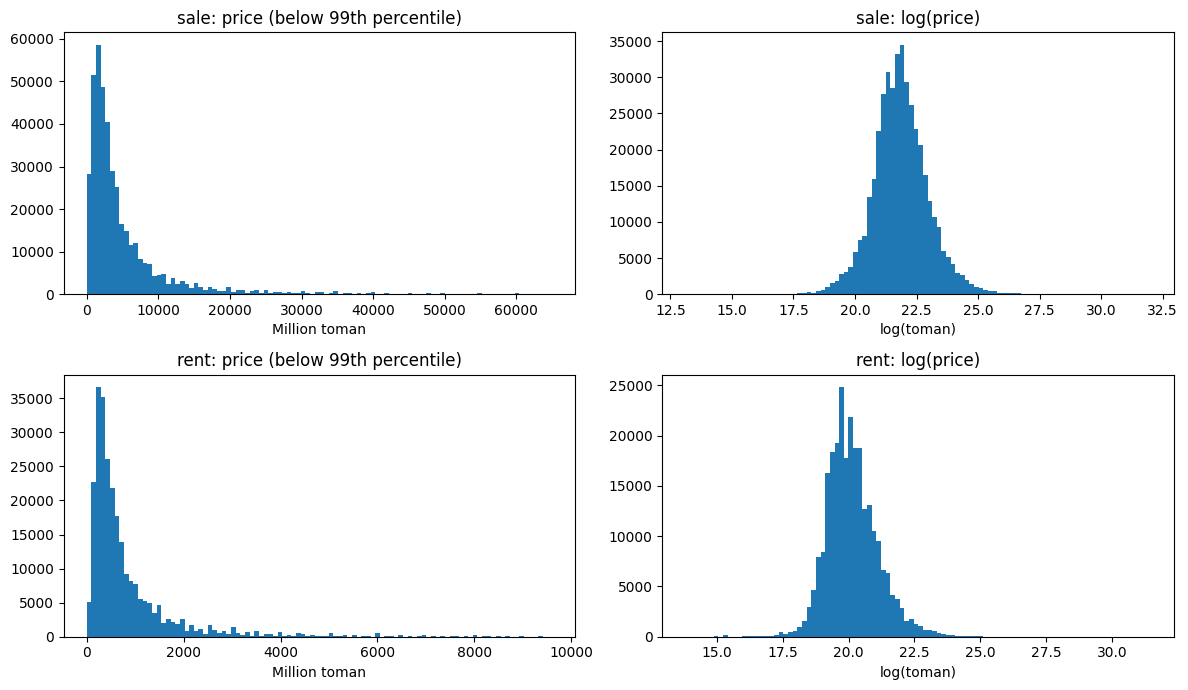

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, deal in enumerate(['sale', 'rent']):
    prices = y_train[X_train['deal_type'] == deal]
    below_p99 = prices[prices < prices.quantile(0.99)]
    axes[row, 0].hist(below_p99 / 1e6, bins=100)
    axes[row, 0].set_title(f'{deal}: price (below 99th percentile)')
    axes[row, 0].set_xlabel('Million toman')
    axes[row, 1].hist(np.log(prices), bins=100)
    axes[row, 1].set_title(f'{deal}: log(price)')
    axes[row, 1].set_xlabel('log(toman)')
plt.tight_layout()
plt.show()

<div dir="rtl">

قیمت‌ها حدود ۸ مرتبه‌ی بزرگی پخش شده‌اند و توزیعشان به‌شدت چوله به راست است. بعد از log، چولگی برای فروش به ۰.۱۵ و برای اجاره به ۰.۵۲ می‌رسد، پس مدل‌ها روی log قیمت آموزش می‌بینند. همه‌ی قیمت‌ها مثبت‌اند، پس `np.log` کافی است.

</div>

In [20]:
y_train_log = np.log(y_train)
y_val_log = np.log(y_val)
y_test_log = np.log(y_test)

## Missing Values

<div dir="rtl">

در پیش‌پردازش هیچ مقدار missingی پر نشده است. اینجا سهم missing هر feature به دو بخش تقسیم می‌شود: فرم آن دسته اصلاً این فیلد را ندارد (مثل طبقه برای زمین)، یا فیلد هست و آگهی‌دهنده آن را خالی گذاشته.

</div>

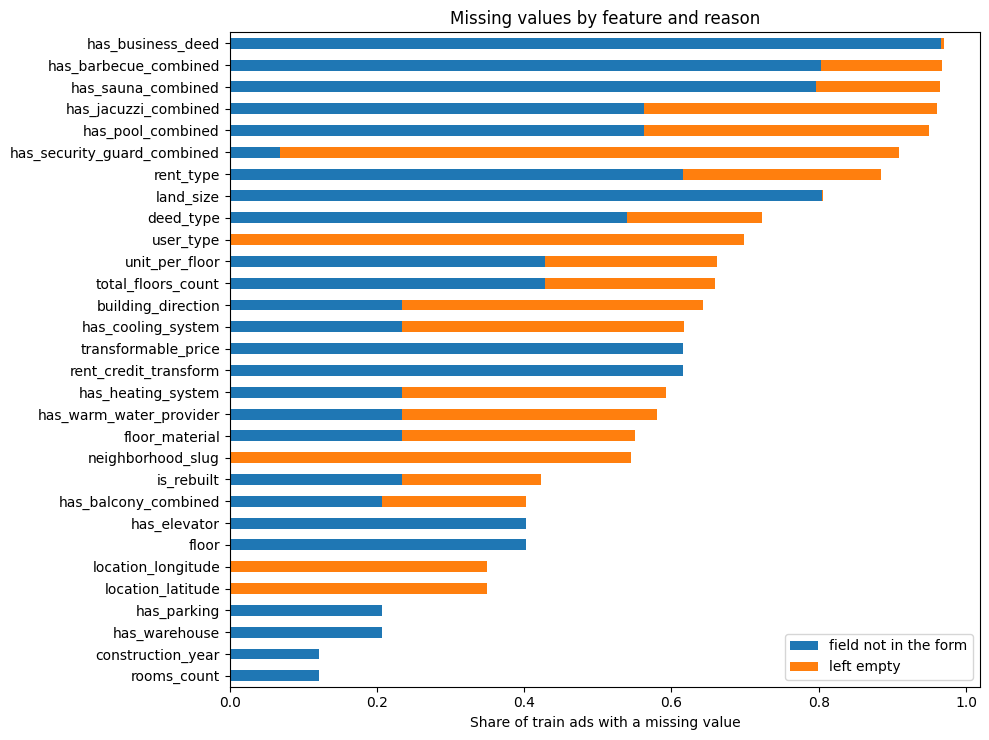

In [21]:
features = numeric_cols + bool_cols + form_cols + ['neighborhood_slug']
missing = X_train[features].isna()
fill_rate = X_train[features].notna().groupby(X_train['cat3_slug']).mean()
# a category has a field if at least 2% of its ads fill it
in_form = (fill_rate >= 0.02).loc[X_train['cat3_slug']].set_axis(X_train.index)
missing_share = pd.DataFrame({'field not in the form': (missing & ~in_form).mean(),
                              'left empty': (missing & in_form).mean()})
missing_share = missing_share[missing_share.sum(axis=1) > 0]
missing_share = missing_share.loc[missing_share.sum(axis=1).sort_values().index]

ax = missing_share.plot(kind='barh', stacked=True, figsize=(10, 7.5))
ax.set_xlabel('Share of train ads with a missing value')
ax.set_title('Missing values by feature and reason')
plt.tight_layout()
plt.show()

In [22]:
main_features = ['rooms_count', 'construction_year', 'floor', 'has_elevator', 'has_parking', 'has_warehouse']
missing_share.loc[main_features].round(3)

,field not in the form,left empty
rooms_count,0.121,0.001
construction_year,0.121,0.001
floor,0.402,0.000
has_elevator,0.402,0.000
has_parking,0.207,0.000
has_warehouse,0.207,0.000


In [23]:
X_train[features].notna().all(axis=1).mean()

np.float64(0.0)

<div dir="rtl">

- در featureهای اصلی (تعداد اتاق، سال ساخت، طبقه، آسانسور، پارکینگ و انباری) تقریباً همه‌ی missing از نوع اول است: آن فیلد برای آن نوع ملک وجود ندارد و مقدار واقعی‌ای برای حدس زدن نیست.
- missing نوع دوم در فیلدهای اختیاری فرم، امکانات، محله و مختصات است.
- هیچ ردیفی در همه‌ی featureها مقدار ندارد، پس حذف ردیف‌های دارای missing ممکن نیست.
- مدل‌های خطی: ستون‌های عددی با median و ستون‌های boolean با صفر پر می‌شوند، و missing در ستون‌های categorical یک دسته‌ی جدا می‌شود. این مقدارها داخل pipeline و فقط از train حساب می‌شوند.
- مدل‌های درختی: missing پر نمی‌شود، چون LightGBM و CatBoost در هر split یاد می‌گیرند ردیف‌های missing را به کدام شاخه بفرستند.
- اثر این دو انتخاب بعد از ساخت هر مدل روی validation سنجیده می‌شود.

</div>

## Outliers

<div dir="rtl">

- معیار outlier، log قیمت هر متر است، چون هم خطای قیمت را نشان می‌دهد هم خطای متراژ.
- حدهای IQR برای هر ترکیب `cat3_slug` و `is_metro` جدا و فقط از train حساب می‌شوند.
- outlierها فقط از train مدل‌های خطی حذف می‌شوند و validation و test دست نمی‌خورند.

</div>

In [24]:
def iqr_outliers(values, groups):
    q1 = values.groupby(groups).transform('quantile', 0.25)
    q3 = values.groupby(groups).transform('quantile', 0.75)
    iqr = q3 - q1
    return (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)

In [25]:
price_per_m2 = y_train / X_train['building_size']
groups = [X_train['cat3_slug'], X_train['is_metro']]
pd.Series({'price per m2': iqr_outliers(price_per_m2, groups).mean(),
           'log(price per m2)': iqr_outliers(np.log(price_per_m2), groups).mean()}).round(3)

,0
price per m2,0.062
log(price per m2),0.022


In [26]:
(price_per_m2.groupby(groups).median() / 1e6).unstack().round(1)

is_metro,0.0,1.0
cat3_slug,,
apartment-rent,4.3,8.2
apartment-sell,27.8,51.4
house-villa-rent,2.9,3.9
house-villa-sell,21.4,28.4
industry-agriculture-business-rent,2.0,2.8
industry-agriculture-business-sell,1.4,5.5
office-rent,6.4,14.3
office-sell,50.3,116.7
plot-old,4.3,6.6


In [27]:
log_price_per_m2 = np.log(price_per_m2)
outlier = iqr_outliers(log_price_per_m2, groups)

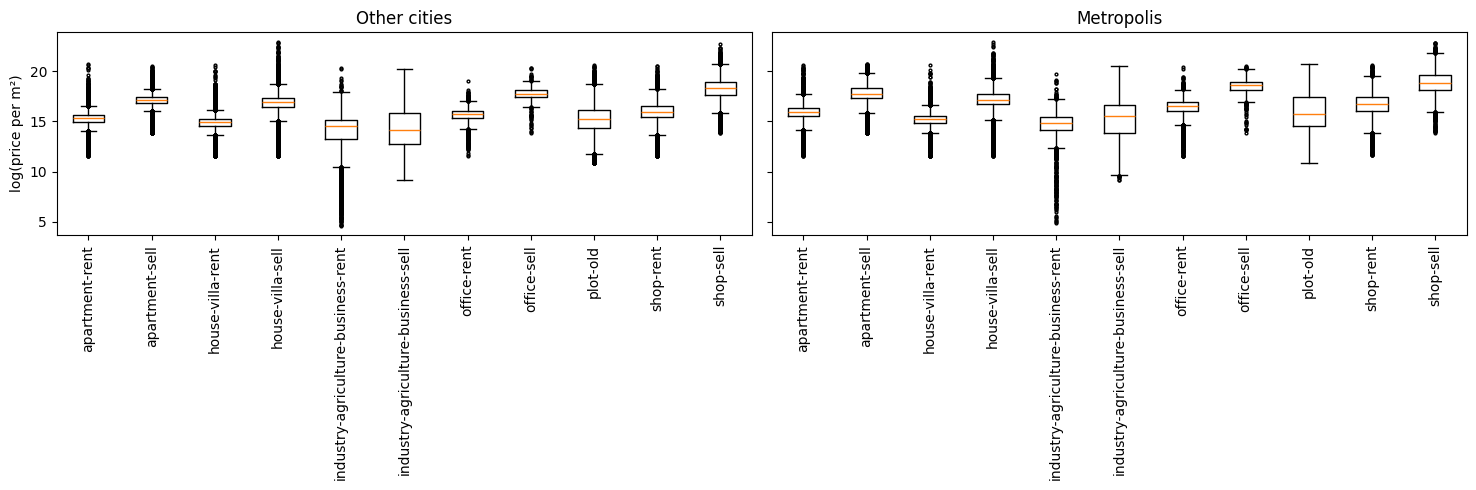

In [28]:
cats = sorted(X_train['cat3_slug'].unique())
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, metro in zip(axes, [0, 1]):
    in_group = X_train['is_metro'] == metro
    ax.boxplot([log_price_per_m2[in_group & (X_train['cat3_slug'] == c)] for c in cats], flierprops={'markersize': 2})
    ax.set_xticks(range(1, len(cats) + 1), cats, rotation=90)
    ax.set_title('Metropolis' if metro else 'Other cities')
axes[0].set_ylabel('log(price per m²)')
plt.tight_layout()
plt.show()

In [29]:
X_train_clean = X_train[~outlier]
y_train_clean_log = y_train_log[~outlier]
X_train_clean.shape

(670311, 48)

In [30]:
X_train_clean['deal_type'].value_counts()

,count
deal_type,
sale,412897
rent,257414


## General Model (Baseline)

<div dir="rtl">

- یک مدل `LinearRegression` برای فروش و اجاره با هم. نوع معامله از `cat3_slug` معلوم است (مثلاً `apartment-sell` و `apartment-rent`).
- متراژ با log وارد مدل می‌شود، چون هدف هم log قیمت است.
- missing در ستون‌های عددی با median و در ستون‌های boolean با صفر پر می‌شود. شهرها و محله‌هایی که کمتر از ۰.۱ درصد آگهی‌ها را دارند، در یک دسته‌ی مشترک قرار می‌گیرند.

</div>

In [31]:
def linear_model():
    features = ColumnTransformer([
        ('size', FunctionTransformer(np.log, feature_names_out='one-to-one'), ['building_size']),
        ('num', SimpleImputer(strategy='median'), ['rooms_count', 'construction_year', 'floor', 'month']),
        ('flag', SimpleImputer(strategy='constant', fill_value=0, keep_empty_features=True), bool_cols + keyword_cols),
        ('cat', OneHotEncoder(min_frequency=0.001, handle_unknown='infrequent_if_exist'), cat_cols)])
    return make_pipeline(features, LinearRegression())

In [32]:
def evaluate(y_true_log, y_pred_log):
    y_true, y_pred = np.exp(y_true_log), np.exp(y_pred_log)
    return {'R2 (log)': r2_score(y_true_log, y_pred_log),
            'R2': r2_score(y_true, y_pred),
            'MAE (M toman)': mean_absolute_error(y_true, y_pred) / 1e6,
            'MSE (M toman²)': mean_squared_error(y_true / 1e6, y_pred / 1e6)}

In [33]:
general = linear_model().fit(X_train_clean, y_train_clean_log)
results = {}
for deal in ['sale', 'rent']:
    in_val = X_val['deal_type'] == deal
    results[deal] = evaluate(y_val_log[in_val], general.predict(X_val[in_val]))
pd.DataFrame(results).T.round(3)

,R2 (log),R2,MAE (M toman),MSE (M toman²)
sale,0.549,0.212,3554.157,4.431839e+08
rent,0.683,0.175,459.738,1.149772e+07


In [34]:
def top10_share(prices):
    squares = (prices - prices.mean()) ** 2
    return squares.nlargest(10).sum() / squares.sum()

y_val.groupby(X_val['deal_type']).apply(top10_share).round(2)

,unified_price
deal_type,
rent,0.65
sale,0.41


<div dir="rtl">

در validation، ده آگهیِ گران‌ترین ۴۱ درصد مجموع مربعات فروش و ۶۵ درصد اجاره را می‌سازند. پس R² و MSE تومانی را عملاً همین چند آگهی تعیین می‌کنند، و برای مقایسه‌ی مدل‌ها از R² روی log استفاده می‌شود.

</div>

### Imputation Choice

<div dir="rtl">

همان مدل baseline با چند روش دیگرِ پر کردن missing آموزش داده می‌شود. عدد جدول R² روی log در validation است.

</div>

In [35]:
flag_indicator = SimpleImputer(strategy='constant', fill_value=0, keep_empty_features=True, add_indicator=True)
options = {
    'median, flags 0 (used)': {},
    'mean, flags 0': {'columntransformer__num': SimpleImputer(strategy='mean')},
    'median, flags most frequent': {'columntransformer__flag': SimpleImputer(strategy='most_frequent')},
    'median, flags 0 + missing indicators': {'columntransformer__num': SimpleImputer(strategy='median', add_indicator=True),
                                             'columntransformer__flag': flag_indicator}}
results = {}
for name, params in options.items():
    model = linear_model().set_params(**params).fit(X_train_clean, y_train_clean_log)
    results[name] = {}
    for deal in ['sale', 'rent']:
        in_val = X_val['deal_type'] == deal
        results[name][deal] = r2_score(y_val_log[in_val], model.predict(X_val[in_val]))
pd.DataFrame(results).T.round(4)

,sale,rent
"median, flags 0 (used)",0.5491,0.6830
"mean, flags 0",0.5491,0.6830
"median, flags most frequent",0.5489,0.6831
"median, flags 0 + missing indicators",0.5497,0.6831


<div dir="rtl">

- اختلاف روش‌ها کمتر از ۰.۰۰۱ است. missing بودن این ستون‌ها را نوع ملک تعیین می‌کند و `cat3_slug` در مدل هست، پس عددی که جای missing گذاشته می‌شود در ضریب همان دسته جذب می‌شود.
- ساده‌ترین روش (median و صفر) نگه داشته می‌شود.

</div>

### Outlier Removal

<div dir="rtl">

مدل baseline یک بار هم روی کل train (با outlierها) آموزش داده می‌شود. هر دو مدل هم روی کل validation سنجیده می‌شوند و هم فقط روی آگهی‌های داخل حدهای IQR.

</div>

In [36]:
# IQR fences from train, applied to validation
fences = log_price_per_m2.groupby(groups).quantile([0.25, 0.75]).unstack()
fences.columns = ['q1', 'q3']
fences['low'] = fences['q1'] - 1.5 * (fences['q3'] - fences['q1'])
fences['high'] = fences['q3'] + 1.5 * (fences['q3'] - fences['q1'])
val_fences = X_val[['cat3_slug', 'is_metro']].join(fences[['low', 'high']], on=['cat3_slug', 'is_metro'])
val_inside = np.log(y_val / X_val['building_size']).between(val_fences['low'], val_fences['high'])
val_inside.mean().round(3)

np.float64(0.978)

In [37]:
general_all = linear_model().fit(X_train, y_train_log)
results = {}
for deal in ['sale', 'rent']:
    in_val = X_val['deal_type'] == deal
    for part, rows in [('all validation', in_val), ('inside IQR fences', in_val & val_inside)]:
        for name, model in [('outliers removed', general), ('all train', general_all)]:
            scores = evaluate(y_val_log[rows], model.predict(X_val[rows]))
            results[(deal, part, name)] = {'R2 (log)': scores['R2 (log)'], 'MAE (M toman)': scores['MAE (M toman)']}
pd.DataFrame(results).T.round({'R2 (log)': 3, 'MAE (M toman)': 0})

R2 (log)  MAE (M toman)
sale all validation    outliers removed     0.549         3554.0
                       all train            0.555         3547.0
     inside IQR fences outliers removed     0.580         3226.0
                       all train            0.581         3241.0
rent all validation    outliers removed     0.683          460.0
                       all train            0.684          452.0
     inside IQR fences outliers removed     0.768          359.0
                       all train            0.754          374.0

<div dir="rtl">

- ۹۷.۸ درصد آگهی‌های validation داخل حدهای IQR هستند. روی این آگهی‌ها حذف outlier مدل اجاره را بهتر می‌کند (R² روی log از ۰.۷۵۴ به ۰.۷۶۸ و MAE از ۳۷۴ به ۳۵۹ میلیون تومان) و مدل فروش تقریباً تغییری نمی‌کند.
- روی کل validation دو مدل تقریباً برابرند (فروش ۰.۵۴۹ در برابر ۰.۵۵۵)، چون مدلی که outlier ندیده روی همان ۲ درصد آگهی بیشتر خطا می‌کند.
- مدل‌های خطی روی train بدون outlier می‌مانند، چون برای آگهی‌های عادی دقیق‌ترند.

</div>

### General vs Separate

<div dir="rtl">

همین مدل یک بار هم جداگانه برای فروش و اجاره آموزش داده می‌شود.

</div>

In [38]:
models = {'general': general}
for deal in ['sale', 'rent']:
    in_train = X_train_clean['deal_type'] == deal
    models[deal] = linear_model().fit(X_train_clean[in_train], y_train_clean_log[in_train])

results = {}
for deal in ['sale', 'rent']:
    in_val = X_val['deal_type'] == deal
    results[(deal, 'general')] = evaluate(y_val_log[in_val], general.predict(X_val[in_val]))
    results[(deal, 'separate')] = evaluate(y_val_log[in_val], models[deal].predict(X_val[in_val]))
pd.DataFrame(results).T.round(3)

R2 (log)     R2  MAE (M toman)  MSE (M toman²)
sale general      0.549  0.212       3554.157    4.431839e+08
     separate     0.555  0.205       3560.964    4.469460e+08
rent general      0.683  0.175        459.738    1.149772e+07
     separate     0.686 -2.589        534.567    4.998795e+07

In [39]:
coefs = {}
for name, model in models.items():
    feature_names = model[0].get_feature_names_out()
    coefs[name] = pd.Series(model[-1].coef_, index=feature_names)
coefs = pd.DataFrame(coefs)
coefs.loc[['size__building_size', 'num__rooms_count', 'flag__has_parking', 'flag__has_elevator',
           'flag__mentions_new_building', 'flag__mentions_agency']].round(3)

,general,sale,rent
size__building_size,0.558,0.497,0.721
num__rooms_count,0.193,0.254,0.086
flag__has_parking,0.202,0.259,0.151
flag__has_elevator,0.182,0.203,0.177
flag__mentions_new_building,0.090,0.097,0.069
flag__mentions_agency,0.140,0.154,0.111


<div dir="rtl">

- دقت مدل کلی و مدل‌های جدا روی log تقریباً یکی است، چون مدل کلی هم نوع معامله را از `cat3_slug` می‌فهمد.
- ولی ضرایب خیلی فرق دارند. مثلاً دو برابر شدن متراژ، قیمت فروش را حدود ۴۱ درصد و اجاره را حدود ۶۵ درصد بالا می‌برد، و مدل کلی برای هر دو ۴۷ درصد می‌دهد.
- برای همین از اینجا فروش و اجاره جدا مدل می‌شوند.

</div>

## Separate Models

<div dir="rtl">

از اینجا فروش و اجاره جدا مدل می‌شوند.

</div>

### Encoding, Product and Power Features

<div dir="rtl">

- شهر و محله با `TargetEncoder` به میانگین log قیمت تبدیل می‌شوند. cross-fitting داخلی آن جلوی نشت قیمت هر آگهی را می‌گیرد.
- `PolynomialFeatures` با درجه‌ی ۲، توان دوم و ضرب دوبه‌دوی متراژ، ستون‌های عددی و `cat3_slug` را می‌سازد.

</div>

In [40]:
X_train[['city_slug', 'neighborhood_slug']].nunique()

,0
city_slug,419
neighborhood_slug,1174


In [41]:
def linear_features(degree):
    numeric = make_pipeline(
        ColumnTransformer([
            ('size', FunctionTransformer(np.log, feature_names_out='one-to-one'), ['building_size']),
            ('num', SimpleImputer(strategy='median'), ['rooms_count', 'construction_year', 'floor', 'month']),
            ('cat3', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['cat3_slug'])],
            verbose_feature_names_out=False),
        PolynomialFeatures(degree=degree, include_bias=False))
    return ColumnTransformer([
        ('numeric', numeric, ['building_size', 'rooms_count', 'construction_year', 'floor', 'month', 'cat3_slug']),
        ('flag', SimpleImputer(strategy='constant', fill_value=0, keep_empty_features=True), bool_cols + keyword_cols),
        ('location', TargetEncoder(target_type='continuous', random_state=42), ['city_slug', 'neighborhood_slug'])],
        verbose_feature_names_out=False)

In [42]:
results = {}
linear_models = {}
for deal in ['sale', 'rent']:
    tr = X_train_clean['deal_type'] == deal
    va = X_val['deal_type'] == deal
    candidates = {'one-hot': linear_model(),
                  'target encoding': make_pipeline(linear_features(degree=1), LinearRegression()),
                  'target encoding + poly': make_pipeline(linear_features(degree=2), LinearRegression())}
    for name, model in candidates.items():
        model.fit(X_train_clean[tr], y_train_clean_log[tr])
        results[(deal, name)] = evaluate(y_val_log[va], model.predict(X_val[va]))
        linear_models[(deal, name)] = model
pd.DataFrame(results).T.round(3)

R2 (log)     R2  MAE (M toman)  MSE (M toman²)
sale one-hot                    0.555  0.205       3560.964    4.469460e+08
     target encoding            0.579  0.226       3406.540    4.352753e+08
     target encoding + poly     0.595  0.106       3377.317    5.025276e+08
rent one-hot                    0.686 -2.589        534.567    4.998795e+07
     target encoding            0.697 -1.379        498.667    3.313279e+07
     target encoding + poly     0.716 -0.234        420.269    1.718120e+07

In [43]:
names = linear_models[('sale', 'target encoding + poly')][0].get_feature_names_out()
[n for n in names if 'building_size' in n][:12]

['building_size',
 'building_size^2',
 'building_size rooms_count',
 'building_size construction_year',
 'building_size floor',
 'building_size month',
 'building_size cat3_slug_apartment-sell',
 'building_size cat3_slug_house-villa-sell',
 'building_size cat3_slug_industry-agriculture-business-sell',
 'building_size cat3_slug_office-sell',
 'building_size cat3_slug_plot-old',
 'building_size cat3_slug_shop-sell']

<div dir="rtl">

- target encoding با ستون‌های خیلی کمتر از one-hot نتیجه‌ی بهتری می‌دهد.
- featureهای ضرب و توان R² روی log و MAE را برای هر دو گروه بهتر می‌کنند.
- R² تومانی همچنان به چند آگهی خیلی گران وابسته است.

</div>

### Dimension Reduction (PCA)

<div dir="rtl">

- ستون‌های poly به هم وابسته‌اند، مثلاً هر ستون با توان دومش. PCA آن‌ها را به مؤلفه‌های ناهمبسته تبدیل می‌کند. قبل از PCA همه‌ی ستون‌ها standardize می‌شوند.
- تعداد مؤلفه‌ها با R² روی validation انتخاب می‌شود.

</div>

In [44]:
explained = {}
pca_r2 = {}
for deal in ['sale', 'rent']:
    tr = X_train_clean['deal_type'] == deal
    va = X_val['deal_type'] == deal
    features = make_pipeline(linear_features(degree=2), StandardScaler())
    Z_train = features.fit_transform(X_train_clean[tr], y_train_clean_log[tr])
    Z_val = features.transform(X_val[va])

    pca = PCA().fit(Z_train)
    P_train, P_val = pca.transform(Z_train), pca.transform(Z_val)
    explained[deal] = np.cumsum(pca.explained_variance_ratio_)

    pca_r2[deal] = {}
    for k in [5, 10, 20, 30, 40, 50, 60, 80]:
        model = LinearRegression().fit(P_train[:, :k], y_train_clean_log[tr])
        pca_r2[deal][k] = r2_score(y_val_log[va], model.predict(P_val[:, :k]))

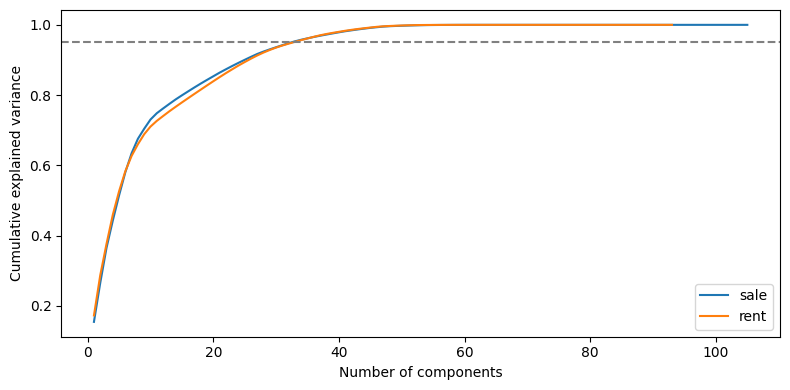

In [45]:
fig, ax = plt.subplots(figsize=(8, 4))
for deal, curve in explained.items():
    ax.plot(range(1, len(curve) + 1), curve, label=deal)
ax.axhline(0.95, color='grey', linestyle='--')
ax.set_xlabel('Number of components')
ax.set_ylabel('Cumulative explained variance')
ax.legend()
plt.tight_layout()
plt.show()

In [46]:
pd.DataFrame(pca_r2).round(3)

,sale,rent
5,0.164,0.298
10,0.425,0.620
20,0.528,0.641
30,0.535,0.649
40,0.575,0.684
50,0.585,0.702
60,0.592,0.715
80,0.595,0.716


<div dir="rtl">

- ۹۵ درصد واریانس با حدود ۳۰ مؤلفه حفظ می‌شود، ولی R² با این تعداد خیلی پایین‌تر است.
- با ۶۰ مؤلفه R² به مقدار کل featureها می‌رسد، پس مدل خطی نهایی PCA با ۶۰ مؤلفه دارد.

</div>

In [47]:
linear_final = {}
results = {}
for deal in ['sale', 'rent']:
    tr = X_train_clean['deal_type'] == deal
    va = X_val['deal_type'] == deal
    model = make_pipeline(linear_features(degree=2), StandardScaler(),
                          PCA(n_components=60, random_state=42), LinearRegression())
    model.fit(X_train_clean[tr], y_train_clean_log[tr])
    results[deal] = evaluate(y_val_log[va], model.predict(X_val[va]))
    linear_final[deal] = model
pd.DataFrame(results).T.round(3)

,R2 (log),R2,MAE (M toman),MSE (M toman²)
sale,0.592,0.087,3408.273,5.135911e+08
rent,0.715,-0.441,428.804,2.007605e+07


## Tree Models

<div dir="rtl">

- LightGBM و CatBoost ستون‌های categorical را خودشان مدیریت می‌کنند، پس شهر، محله، دسته‌ی ملک و ستون‌های متنی فرم مستقیم وارد می‌شوند. missing در این ستون‌ها یک دسته‌ی جدا می‌شود.
- تعداد درخت‌ها با early stopping روی validation تعیین می‌شود.

</div>

### Neighbor Price

<div dir="rtl">

- برای هر آگهی، میانگین log قیمت هر متر ۱۰ آگهی نزدیک از همان دسته در train با `KNeighborsRegressor` حساب می‌شود.
- برای ردیف‌های train این عدد out-of-fold ساخته می‌شود تا قیمت خود آگهی در آن نباشد.

</div>

In [48]:
coords = ['location_latitude', 'location_longitude']
for data in [X_train, X_val, X_test]:
    data['neighbor_price'] = np.nan

for cat in X_train['cat3_slug'].unique():
    fit = (X_train['cat3_slug'] == cat) & X_train['location_latitude'].notna()
    fit_coords = np.radians(X_train.loc[fit, coords])
    target = y_train_log[fit] - np.log(X_train.loc[fit, 'building_size'])
    knn = KNeighborsRegressor(n_neighbors=10, metric='haversine')
    X_train.loc[fit, 'neighbor_price'] = cross_val_predict(knn, fit_coords, target, cv=5)
    knn.fit(fit_coords, target)
    for data in [X_val, X_test]:
        query = (data['cat3_slug'] == cat) & data['location_latitude'].notna()
        data.loc[query, 'neighbor_price'] = knn.predict(np.radians(data.loc[query, coords]))
X_train['neighbor_price'].notna().groupby(X_train['deal_type']).mean().round(3)

,neighbor_price
deal_type,
rent,0.662
sale,0.644


In [49]:
tree_features = [c for c in X_train.columns if c != 'deal_type']
tree_cat_cols = cat_cols + form_cols

def tree_data(X):
    X = X[tree_features].copy()
    X[tree_cat_cols] = X[tree_cat_cols].fillna('missing').astype('category')
    return X

### Outliers and Tree Models

<div dir="rtl">

اثر حذف outlier روی LightGBM با تنظیم پیش‌فرض سنجیده می‌شود.

</div>

In [50]:
results = {}
for deal in ['sale', 'rent']:
    tr = X_train['deal_type'] == deal
    va = X_val['deal_type'] == deal
    for name, rows in [('outliers removed', tr & ~outlier), ('all train', tr)]:
        model = LGBMRegressor(n_estimators=3000, learning_rate=0.05, num_leaves=63, random_state=42, verbose=-1)
        model.fit(tree_data(X_train[rows]), y_train_log[rows],
                  eval_set=[(tree_data(X_val[va]), y_val_log[va])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
        results[(deal, name)] = evaluate(y_val_log[va], model.predict(tree_data(X_val[va])))
pd.DataFrame(results).T.round(3)

R2 (log)     R2  MAE (M toman)  MSE (M toman²)
sale outliers removed     0.723  0.214       2564.582    4.416970e+08
     all train            0.731  0.494       2444.567    2.846132e+08
rent outliers removed     0.769  0.371        332.968    8.762486e+06
     all train            0.785  0.395        310.683    8.426712e+06

<div dir="rtl">

- برای LightGBM حذف outlier ضرر دارد. با کل train، R² روی log برای فروش از ۰.۷۲۳ به ۰.۷۳۱ و برای اجاره از ۰.۷۶۹ به ۰.۷۸۵ می‌رسد و R² تومانی فروش از ۰.۲۱ به ۰.۴۹.
- پس مدل‌های درختی روی کل train آموزش می‌بینند.

</div>

### Missing Values and Tree Models

<div dir="rtl">

همان LightGBM یک بار با missing پرنشده و یک بار با همان روش مدل‌های خطی (median و صفر) آموزش داده می‌شود.

</div>

In [51]:
results = {}
for deal in ['sale', 'rent']:
    tr = X_train['deal_type'] == deal
    va = X_val['deal_type'] == deal
    Z_train, Z_val = tree_data(X_train[tr]), tree_data(X_val[va])
    fill = Z_train.median(numeric_only=True)
    fill[bool_cols + keyword_cols] = 0
    data = {'missing kept': (Z_train, Z_val),
            'missing filled': (Z_train.fillna(fill), Z_val.fillna(fill))}
    for name, (train_part, val_part) in data.items():
        model = LGBMRegressor(n_estimators=3000, learning_rate=0.05, num_leaves=63, random_state=42, verbose=-1)
        model.fit(train_part, y_train_log[tr], eval_set=[(val_part, y_val_log[va])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
        results[(deal, name)] = evaluate(y_val_log[va], model.predict(val_part))
pd.DataFrame(results).T.round(3)

R2 (log)     R2  MAE (M toman)  MSE (M toman²)
sale missing kept       0.731  0.494       2444.567    2.846132e+08
     missing filled     0.731  0.420       2482.981    3.263237e+08
rent missing kept       0.785  0.395        310.683    8.426712e+06
     missing filled     0.785  0.400        307.746    8.362533e+06

<div dir="rtl">

- ردیف `missing kept` همان مدل `all train` جدول قبل است.
- R² روی log در دو حالت یکی است (فروش ۰.۷۳۱ و اجاره ۰.۷۸۵). پر کردن missing در فروش MAE را از ۲,۴۴۵ به ۲,۴۸۳ میلیون تومان بدتر می‌کند و در اجاره تغییر مهمی نمی‌دهد.
- پر کردن سودی ندارد، پس مدل‌های درختی با missing پرنشده آموزش می‌بینند.

</div>

## Hyperparameter Search

<div dir="rtl">

- برای هر مدل چند ترکیب تصادفی از hyperparameterها امتحان می‌شود (`ParameterSampler`) و ترکیبی که بیشترین R² روی log را در validation دارد انتخاب می‌شود.
- search روی یک زیرنمونه‌ی ۱۰۰ هزارتایی از train انجام می‌شود تا زمانش معقول بماند. بعد مدل با بهترین ترکیب روی کل train آموزش می‌بیند.
- در CatBoost ستون‌هایی که کمتر از ۱۰ مقدار دارند one-hot می‌شوند (`one_hot_max_size=10`) تا آموزش سریع‌تر شود.

</div>

In [52]:
lgbm_space = {'num_leaves': [31, 63, 127, 255],
              'learning_rate': [0.03, 0.05, 0.1],
              'min_child_samples': [10, 20, 50, 100],
              'colsample_bytree': [0.6, 0.8, 1.0],
              'reg_lambda': [0, 1, 10]}
catboost_space = {'depth': [6, 8],
                  'learning_rate': [0.2, 0.3],
                  'l2_leaf_reg': [1, 3, 10]}

In [53]:
search_rows = {}
for deal in ['sale', 'rent']:
    in_deal = X_train[X_train['deal_type'] == deal]
    search_rows[deal] = in_deal.sample(100_000, random_state=42).index

In [54]:
lgbm_search = []
best_lgbm_params = {}
for deal in ['sale', 'rent']:
    rows = search_rows[deal]
    va = X_val['deal_type'] == deal
    X_tr, y_tr = tree_data(X_train.loc[rows]), y_train_log[rows]
    X_va, y_va = tree_data(X_val[va]), y_val_log[va]
    best_score = -np.inf
    for params in ParameterSampler(lgbm_space, n_iter=12, random_state=42):
        model = LGBMRegressor(n_estimators=3000, random_state=42, verbose=-1, **params)
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(100, verbose=False)])
        score = r2_score(y_va, model.predict(X_va))
        lgbm_search.append({'deal': deal, **params, 'trees': model.best_iteration_, 'R2 (log)': score})
        if score > best_score:
            best_score = score
            best_lgbm_params[deal] = params
lgbm_search = pd.DataFrame(lgbm_search)
lgbm_search.sort_values('R2 (log)', ascending=False).groupby('deal').head(3).round(4)

,deal,reg_lambda,num_leaves,min_child_samples,learning_rate,colsample_bytree,trees,R2 (log)
15,rent,0,127,50,0.03,0.6,331,0.7837
23,rent,1,255,20,0.05,0.6,153,0.7835
13,rent,0,63,50,0.05,0.6,332,0.7821
11,sale,1,255,20,0.05,0.6,248,0.7166
7,sale,1,255,10,0.03,0.8,342,0.7161
10,sale,0,255,10,0.03,0.8,412,0.7159


In [55]:
best_lgbm_params

{'sale': {'reg_lambda': 1,
  'num_leaves': 255,
  'min_child_samples': 20,
  'learning_rate': 0.05,
  'colsample_bytree': 0.6},
 'rent': {'reg_lambda': 0,
  'num_leaves': 127,
  'min_child_samples': 50,
  'learning_rate': 0.03,
  'colsample_bytree': 0.6}}

In [56]:
lgbm_tuned = {}
for deal in ['sale', 'rent']:
    tr = X_train['deal_type'] == deal
    va = X_val['deal_type'] == deal
    model = LGBMRegressor(n_estimators=5000, random_state=42, verbose=-1, **best_lgbm_params[deal])
    model.fit(tree_data(X_train[tr]), y_train_log[tr],
              eval_set=[(tree_data(X_val[va]), y_val_log[va])],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    lgbm_tuned[deal] = model
{deal: m.best_iteration_ for deal, m in lgbm_tuned.items()}

{'sale': 412, 'rent': 538}

In [57]:
catboost_search = []
best_catboost_params = {}
for deal in ['sale', 'rent']:
    rows = search_rows[deal]
    va = X_val['deal_type'] == deal
    X_tr, y_tr = tree_data(X_train.loc[rows]), y_train_log[rows]
    X_va, y_va = tree_data(X_val[va]), y_val_log[va]
    best_score = -np.inf
    for params in ParameterSampler(catboost_space, n_iter=5, random_state=42):
        model = CatBoostRegressor(iterations=3000, cat_features=tree_cat_cols, one_hot_max_size=10,
                                  early_stopping_rounds=100, random_seed=42, verbose=0, **params)
        model.fit(X_tr, y_tr, eval_set=(X_va, y_va))
        score = r2_score(y_va, model.predict(X_va))
        catboost_search.append({'deal': deal, **params, 'trees': model.best_iteration_, 'R2 (log)': score})
        if score > best_score:
            best_score = score
            best_catboost_params[deal] = params
catboost_search = pd.DataFrame(catboost_search)
catboost_search.sort_values('R2 (log)', ascending=False).groupby('deal').head(3).round(4)

,deal,learning_rate,l2_leaf_reg,depth,trees,R2 (log)
7,rent,0.2,1,6,697,0.7777
5,rent,0.2,10,8,333,0.7773
9,rent,0.3,10,6,561,0.7768
2,sale,0.2,1,6,1214,0.7084
3,sale,0.2,3,8,686,0.7083
0,sale,0.2,10,8,699,0.7080


In [58]:
best_catboost_params

{'sale': {'learning_rate': 0.2, 'l2_leaf_reg': 1, 'depth': 6},
 'rent': {'learning_rate': 0.2, 'l2_leaf_reg': 1, 'depth': 6}}

In [59]:
catboost_tuned = {}
for deal in ['sale', 'rent']:
    tr = X_train['deal_type'] == deal
    va = X_val['deal_type'] == deal
    model = CatBoostRegressor(iterations=5000, cat_features=tree_cat_cols, one_hot_max_size=10,
                              early_stopping_rounds=100, random_seed=42, verbose=0, **best_catboost_params[deal])
    model.fit(tree_data(X_train[tr]), y_train_log[tr], eval_set=(tree_data(X_val[va]), y_val_log[va]))
    catboost_tuned[deal] = model
{deal: m.best_iteration_ for deal, m in catboost_tuned.items()}

{'sale': 3248, 'rent': 646}

### Validation Comparison

<div dir="rtl">

پیش‌بینی نهایی میانگین پیش‌بینی LightGBM و CatBoost است.

</div>

In [60]:
def blend_predict(deal, X):
    Z = tree_data(X)
    return (lgbm_tuned[deal].predict(Z) + catboost_tuned[deal].predict(Z)) / 2

In [61]:
results = {}
for deal in ['sale', 'rent']:
    va = X_val['deal_type'] == deal
    results[(deal, 'linear (poly + PCA)')] = evaluate(y_val_log[va], linear_final[deal].predict(X_val[va]))
    results[(deal, 'LightGBM')] = evaluate(y_val_log[va], lgbm_tuned[deal].predict(tree_data(X_val[va])))
    results[(deal, 'CatBoost')] = evaluate(y_val_log[va], catboost_tuned[deal].predict(tree_data(X_val[va])))
    results[(deal, 'LightGBM + CatBoost')] = evaluate(y_val_log[va], blend_predict(deal, X_val[va]))
pd.DataFrame(results).T.round(3)

R2 (log)     R2  MAE (M toman)  MSE (M toman²)
sale linear (poly + PCA)     0.592  0.087       3408.273    5.135911e+08
     LightGBM                0.737  0.467       2416.486    2.994336e+08
     CatBoost                0.729  0.399       2565.340    3.380774e+08
     LightGBM + CatBoost     0.739  0.449       2432.338    3.096774e+08
rent linear (poly + PCA)     0.715 -0.441        428.804    2.007605e+07
     LightGBM                0.789  0.413        305.543    8.175164e+06
     CatBoost                0.785  0.500        312.761    6.962471e+06
     LightGBM + CatBoost     0.791  0.455        303.768    7.595832e+06

<div dir="rtl">

- مدل‌های درختی خیلی بهتر از مدل خطی‌اند.
- میانگین LightGBM و CatBoost در هر دو گروه بیشترین R² روی log را دارد و مدل نهایی است.

</div>

## Final Evaluation on Test

<div dir="rtl">

مدل‌ها فقط یک بار روی test سنجیده می‌شوند.

</div>

In [62]:
results = {}
for deal in ['sale', 'rent']:
    te = X_test['deal_type'] == deal
    results[(deal, 'baseline (general linear)')] = evaluate(y_test_log[te], general.predict(X_test[te]))
    results[(deal, 'linear (poly + PCA)')] = evaluate(y_test_log[te], linear_final[deal].predict(X_test[te]))
    results[(deal, 'LightGBM + CatBoost')] = evaluate(y_test_log[te], blend_predict(deal, X_test[te]))
pd.DataFrame(results).T.round(3)

R2 (log)     R2  MAE (M toman)  MSE (M toman²)
sale baseline (general linear)     0.549  0.218       3600.810    4.690345e+08
     linear (poly + PCA)           0.590 -0.486       3472.787    8.915810e+08
     LightGBM + CatBoost           0.734  0.469       2471.834    3.186867e+08
rent baseline (general linear)     0.685  0.071        479.834    4.035219e+07
     linear (poly + PCA)           0.715 -0.042        445.848    4.526510e+07
     LightGBM + CatBoost           0.798  0.205        322.737    3.454584e+07

### Effect of Extreme Ads

<div dir="rtl">

همان حدهای IQR که از train به دست آمد روی test اعمال می‌شود تا معلوم شود معیارها چقدر به آگهی‌های بیرون از این حدها وابسته‌اند. این فقط برای تحلیل است و مدل تغییری نمی‌کند.

</div>

In [63]:
fences = log_price_per_m2.groupby(groups).quantile([0.25, 0.75]).unstack()
fences.columns = ['q1', 'q3']
fences['low'] = fences['q1'] - 1.5 * (fences['q3'] - fences['q1'])
fences['high'] = fences['q3'] + 1.5 * (fences['q3'] - fences['q1'])

test_fences = X_test[['cat3_slug', 'is_metro']].join(fences[['low', 'high']], on=['cat3_slug', 'is_metro'])
test_log_price_per_m2 = np.log(y_test / X_test['building_size'])
inside = test_log_price_per_m2.between(test_fences['low'], test_fences['high'])
inside.groupby(X_test['deal_type']).mean().round(3)

,0
deal_type,
rent,0.976
sale,0.980


In [64]:
results = {}
for deal in ['sale', 'rent']:
    te = X_test['deal_type'] == deal
    results[(deal, 'all test ads')] = evaluate(y_test_log[te], blend_predict(deal, X_test[te]))
    results[(deal, 'inside IQR fences')] = evaluate(y_test_log[te & inside], blend_predict(deal, X_test[te & inside]))
pd.DataFrame(results).T.round(3)

R2 (log)     R2  MAE (M toman)  MSE (M toman²)
sale all test ads          0.734  0.469       2471.834    3.186867e+08
     inside IQR fences     0.758  0.506       2183.034    2.476032e+08
rent all test ads          0.798  0.205        322.737    3.454584e+07
     inside IQR fences     0.858  0.699        240.047    1.852319e+06

### Error by Category

<div dir="rtl">

خطای نسبی هر آگهی برابر قدر مطلق نسبت پیش‌بینی به قیمت واقعی منهای یک است.

</div>

In [65]:
errors = []
for deal in ['sale', 'rent']:
    te = X_test['deal_type'] == deal
    predicted = np.exp(blend_predict(deal, X_test[te]))
    errors.append(pd.DataFrame({'cat3_slug': X_test.loc[te, 'cat3_slug'],
                                'error': abs(predicted / y_test[te] - 1)}))
errors = pd.concat(errors)
errors.groupby('cat3_slug')['error'].agg(['count', 'median']).round(3)

,count,median
cat3_slug,,
apartment-rent,20189,0.120
apartment-sell,28743,0.115
house-villa-rent,6009,0.200
house-villa-sell,10828,0.270
industry-agriculture-business-rent,730,0.424
industry-agriculture-business-sell,742,0.610
office-rent,1888,0.205
office-sell,393,0.229
plot-old,10347,0.502


### Predicted vs Actual

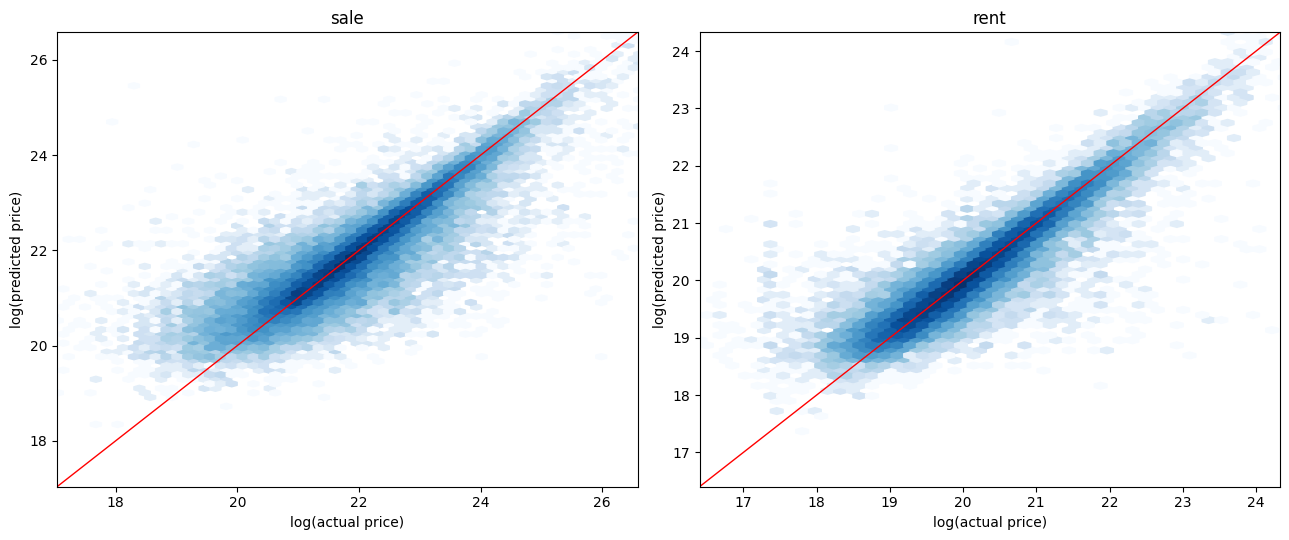

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, deal in zip(axes, ['sale', 'rent']):
    te = X_test['deal_type'] == deal
    predicted = blend_predict(deal, X_test[te])
    ax.hexbin(y_test_log[te], predicted, gridsize=80, bins='log', cmap='Blues')
    low, high = y_test_log[te].quantile([0.001, 0.999])
    ax.plot([low, high], [low, high], color='red', linewidth=1)
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_title(deal)
    ax.set_xlabel('log(actual price)')
    ax.set_ylabel('log(predicted price)')
plt.tight_layout()
plt.show()

### Feature Importance (LightGBM)

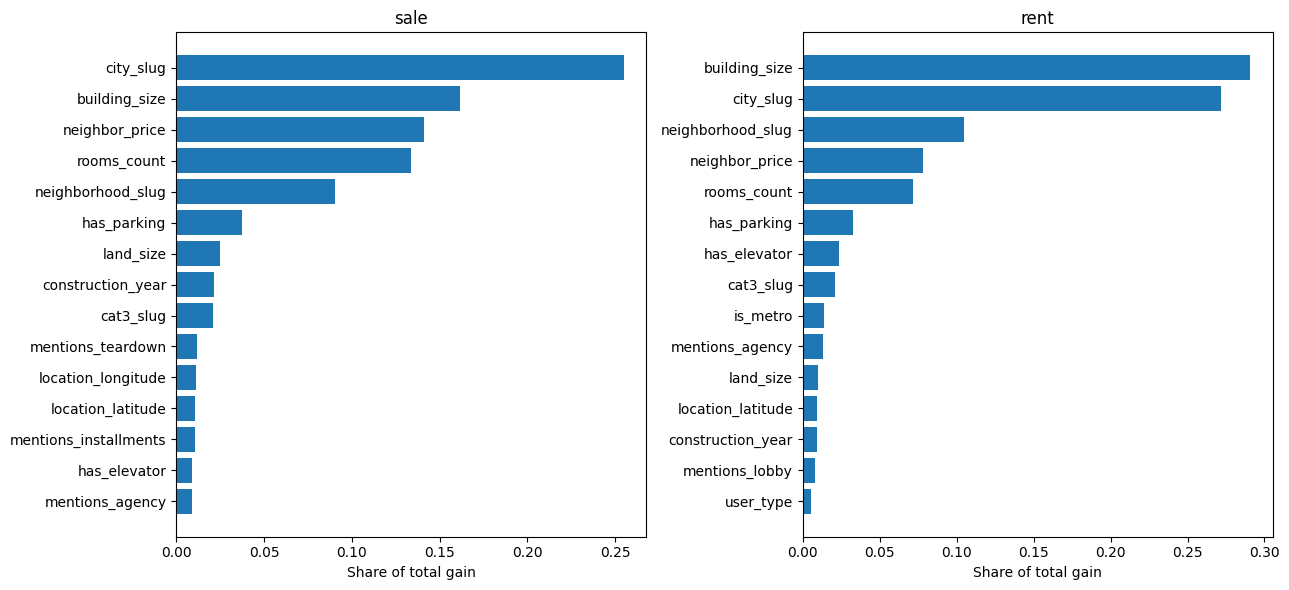

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, deal in zip(axes, ['sale', 'rent']):
    booster = lgbm_tuned[deal].booster_
    importance = pd.Series(booster.feature_importance('gain'), index=booster.feature_name())
    importance = (importance / importance.sum()).sort_values().tail(15)
    ax.barh(importance.index, importance.values)
    ax.set_title(deal)
    ax.set_xlabel('Share of total gain')
plt.tight_layout()
plt.show()

## Conclusion

<div dir="rtl">

- مدل نهایی روی test، R² روی log را برای فروش از ۰.۵۵ (baseline) به ۰.۷۳ و برای اجاره از ۰.۶۹ به ۰.۸۰ می‌رساند و MAE را حدود ۳۰ درصد کم می‌کند.
- R² تومانی فروش ۰.۴۷ و اجاره ۰.۲۱ است. این عدد به حدود ۲ درصد آگهی‌هایی وابسته است که بیرون حدهای IQR هستند؛ روی بقیه‌ی آگهی‌ها R² تومانی فروش ۰.۵۱ و اجاره ۰.۷۰ است.
- خطای نسبی معمول برای آپارتمان حدود ۱۲ درصد است. زمین، ملک صنعتی و کشاورزی و مغازه خطای خیلی بیشتری دارند (۴۰ تا ۶۰ درصد).
- مهم‌ترین featureها شهر، متراژ، محله و قیمت همسایه‌ها هستند. تعداد اتاق در فروش مهم‌تر از اجاره است.

</div>

## Bonus: Text Feature

<div dir="rtl">

- این بخش از پردازش متن استفاده می‌کند و خارج از سرفصل اصلی است.
- پیش‌بینی یک `Ridge` روی TF-IDF عنوان و توضیح آگهی به‌عنوان feature به LightGBM داده می‌شود (برای train به‌صورت out-of-fold). عددها و کلمه‌های مبلغ قبل از آن از متن حذف می‌شوند.
- کد این بخش comment شده است و اجرا نمی‌شود.

</div>

In [ ]:
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.linear_model import Ridge

In [ ]:
# text = pd.read_parquet('divar_clean.parquet', columns=['title', 'description'])
# text = (text['title'].fillna('') + ' ' + text['description'].fillna('')).loc[X_train.index.append([X_val.index, X_test.index])]
# money_words = 'تومان|تومن|میلیون|ملیون|میلیارد|ملیارد|هزار|قیمت|رهن|اجاره|ودیعه|پول|نقد|مبلغ|فی|متری|توافقی|قسط|اقساط|وام'
# text = text.str.replace(r'[0-9۰-۹٠-٩]+', ' ', regex=True).str.replace(money_words, ' ', regex=True)

In [ ]:
# text_price = {}
# for deal in ['sale', 'rent']:
#     tr = X_train['deal_type'] == deal
#     other = X_val.index[X_val['deal_type'] == deal].append(X_test.index[X_test['deal_type'] == deal])
#     vectorizer = TfidfVectorizer(max_features=30000, min_df=5, sublinear_tf=True)
#     T_train = vectorizer.fit_transform(text.loc[X_train.index[tr]])
#     ridge = Ridge(alpha=3.0)
#     train_part = pd.Series(cross_val_predict(ridge, T_train, y_train_log[tr], cv=5), index=X_train.index[tr])
#     ridge.fit(T_train, y_train_log[tr])
#     other_part = pd.Series(ridge.predict(vectorizer.transform(text.loc[other])), index=other)
#     text_price[deal] = pd.concat([train_part, other_part])

In [ ]:
# lgbm_text = {}
# results = {}
# for deal in ['sale', 'rent']:
#     tr = X_train['deal_type'] == deal
#     va = X_val['deal_type'] == deal
#     te = X_test['deal_type'] == deal
#     Z_train = tree_data(X_train[tr]).assign(text_price=text_price[deal])
#     Z_val = tree_data(X_val[va]).assign(text_price=text_price[deal])
#     Z_test = tree_data(X_test[te]).assign(text_price=text_price[deal])
#     model = LGBMRegressor(n_estimators=5000, random_state=42, verbose=-1, **best_lgbm_params[deal])
#     model.fit(Z_train, y_train_log[tr], eval_set=[(Z_val, y_val_log[va])],
#               callbacks=[lgb.early_stopping(100, verbose=False)])
#     lgbm_text[deal] = model
#     results[(deal, 'val')] = evaluate(y_val_log[va], model.predict(Z_val))
#     results[(deal, 'test')] = evaluate(y_test_log[te], model.predict(Z_test))
# pd.DataFrame(results).T.round(3)